In [1]:
## Open pickle files 

In [1]:
from climada_petals.hazard import TCForecast
import logging
import datetime
import os
import numpy as np
import geopandas as gpd

In [3]:
#pip install -e .

In [2]:
###SUBNATIONAL DIVISION 
import geopandas as gpd
geofile_MOZ = '/cluster/work/climate/gespejo/data/infrastructure/Mozambique_results_MOZ/gadm41_MOZ_shp/gadm41_MOZ_1.shp'
gadm_MOZ = gpd.read_file(geofile_MOZ)

In [3]:
### CREATE POINTS FOR EVERY CI AND PEOPLE 
from climada_petals.hazard.IMP_TRACKFORECAST import convert_to_geodf
gadm_MOZ_gdf = convert_to_geodf(gadm_MOZ, ['NAME_1', 'geometry'])

In [4]:
import pickle 

In [5]:
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/impp1_disrupted.pkl', 'rb') as file:
    impp1_disrupted = pickle.load(file)
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/impp1.pkl', 'rb') as file:
    impp1 = pickle.load(file)

In [7]:
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/disrupted_hospitals.pkl', 'rb') as file:
    disrupted_hospitals = pickle.load(file) 

In [8]:
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/disrupted_schools.pkl', 'rb') as file:
    disrupted_schools = pickle.load(file)

In [9]:
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/rd2_disrupted.pkl', 'rb') as file:
    rd2_disrupted = pickle.load(file)

In [10]:
##################### POPULATION 
from climada.entity.exposures.base import Exposures
#from climada.entity.exposures.base import Exposures
#Exposures.from_raster(path_cntry)
gdf_worldpop_MOZ = Exposures.from_raster('/cluster/work/climate/gespejo/data/infrastructure/population/moz_ppp_2020_1km_Aggregated_UNadj.tif')
#(exposure_pp.gdf.value==0).all()
#exposure_pp_MOZ.gdf
gdf_worldpop_MOZ.set_geometry_points()
###roads original
import geopandas as gpd
gdf_roads_MOZ = gpd.read_feather('/cluster/work/climate/gespejo/data/infrastructure/Mozambique_results_MOZ_2023/road')
# Rename the 'value' column to 'people'
## This one I should do anyway for the nex 
gdf_worldpop_MOZ.gdf.rename(columns={'value': 'people'}, inplace=True)

In [11]:
def calc_mean_for_impdict(impact_dict):
    """
    Given a dictionary of impact objects, calculate the mean impact for all tracks.
    
    Parameters:
        impact_dict (dict): A dictionary where keys are track names and 
                            values are Impact objects.
    
    Returns:
        mean_impacts (dict): A dictionary where keys are track names and values
                             are numpy arrays representing the mean impacts.
    """
    mean_impacts = {}
    
    for track_name, imp_obj in impact_dict.items():
        # Check if the impact object is valid
        if imp_obj is None:
            raise ValueError(f"No impact object found for track {track_name}")
        
        # Calculate the mean
        mean = imp_obj.imp_mat.mean(axis=0)
        mean_imp = np.ravel(mean).flatten()
        
        # Store the mean impact in the dictionary
        mean_impacts[track_name] = mean_imp
    
    return mean_impacts

In [12]:
impp1_mean = calc_mean_for_impdict(impp1)

In [14]:
impp1_mean ['impp1_MOZ_Kenneth_20190423120000'][1]

0.0

In [15]:
def calc_mean_and_coords_for_impdict(impact_dict, threshold=0.0):
    """
    Given a dictionary of impact objects, calculate the mean impact and return a filtered combined array.

    Parameters:
        impact_dict (dict): A dictionary where keys are track names and 
                            values are Impact objects.
        threshold (float): Minimum mean impact value required to include the exposure in the output.

    Returns:
        result (dict): A dictionary where keys are track names and values are numpy arrays with shape (N_filtered_exposures, 3):
                       [mean_impact, coord_x, coord_y]
    """
    result = {}
    
    for track_name, imp_obj in impact_dict.items():
        if imp_obj is None:
            raise ValueError(f"No impact object found for track {track_name}")
        
        # Mean disruption per exposure
        mean = imp_obj.imp_mat.mean(axis=0)
        mean_imp = np.ravel(mean).flatten()  # shape: (N_exposures,)
        
        # Coordinates per exposure
        coords = imp_obj.coord_exp  # shape: (N_exposures, 2)
        
        # Combine into a single array: [mean_impact, x, y]
        combined = np.column_stack((mean_imp, coords))  # shape: (N_exposures, 3)

        # Filter: keep only rows with mean_impact > threshold
        filtered = combined[combined[:, 0] >= threshold]
        
        result[track_name] = filtered
    
    return result

In [16]:
impp1_mean_coords = calc_mean_and_coords_for_impdict(impp1, threshold=0.05)

In [17]:
def add_people_meanimpact(impp1_keys, gdf_worldpop, gadm_MOZ_gdf):
    """
    Enrich all keys in impp1_mean_coords with population and NAME_1 region data.

    Parameters:
    - impp1_mean_coords (dict): Keys are track IDs, values are NumPy arrays [mean_impact, lat, lon]
    - gdf_worldpop (GeoDataFrame or CLIMADA Exposures): Must include 'geometry' and 'people'
    - gadm_MOZ_gdf (GeoDataFrame): Must include 'geometry' and 'NAME_1'

    Returns:
    - enriched_dict (dict): Dictionary with same keys, each value a GeoDataFrame with:
                            [mean_impact, people, NAME_1, geometry]
    """
    import geopandas as gpd
    from shapely.geometry import Point
    from scipy.spatial import cKDTree
    import numpy as np

    # If CLIMADA Exposures, extract .gdf
    if hasattr(gdf_worldpop, 'gdf'):
        gdf_worldpop = gdf_worldpop.gdf

    # Ensure CRS
    gdf_worldpop = gdf_worldpop.to_crs("EPSG:4326")
    gadm_MOZ_gdf = gadm_MOZ_gdf.to_crs("EPSG:4326")

    # Precompute KDTree for unmatched NAME_1 lookup
    centroids = gadm_MOZ_gdf.geometry.centroid
    centroid_coords = np.array([[pt.x, pt.y] for pt in centroids])
    kdtree = cKDTree(centroid_coords)

    impp1_people_dict = {}

    for key, arr in impp1_keys.items():
        mean_impact = arr[:, 0]
        lat = arr[:, 1]
        lon = arr[:, 2]
        geometry = [Point(xy) for xy in zip(lon, lat)]
        gdf = gpd.GeoDataFrame({'mean_impact': mean_impact}, geometry=geometry, crs="EPSG:4326")

        # Join people from worldpop (exact match)
        gdf = gdf.merge(
            gdf_worldpop[['geometry', 'people']],
            on='geometry',
            how='left'
        )
        gdf['people'] = gdf['people'].fillna(0).astype(int)

        # Join NAME_1 using spatial join
        gdf = gpd.sjoin(
            gdf, gadm_MOZ_gdf[['geometry', 'NAME_1']],
            how='left', predicate='intersects'
        ).drop(columns='index_right')

        # Handle unmatched NAME_1 using KDTree
        unmatched = gdf[gdf['NAME_1'].isna()]
        if not unmatched.empty:
            unmatched_coords = np.array([[pt.x, pt.y] for pt in unmatched.geometry])
            _, nearest_idxs = kdtree.query(unmatched_coords, k=1)
            gdf.loc[unmatched.index, 'NAME_1'] = gadm_MOZ_gdf.iloc[nearest_idxs]['NAME_1'].values

        # Save enriched result
        impp1_people_dict[key] = gdf

    return impp1_people_dict

In [18]:
impp1_people_dict = add_people_meanimpact(
    impp1_mean_coords,
    gdf_worldpop_MOZ.gdf,
    gadm_MOZ_gdf
)

/scratch/tmp.34268694.gespejo/ipykernel_1307551/2587405754.py:28: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centroids = gadm_MOZ_gdf.geometry.centroid


In [20]:
impp1_people_dict ['impp1_MOZ_Kenneth_20190423120000']

,mean_impact,geometry,people,NAME_1
0,0.050850,POINT (40.74458 -11.70458),0,Cabo Delgado
1,0.050850,POINT (40.75292 -11.70458),0,Cabo Delgado
2,0.050850,POINT (40.76125 -11.70458),0,Cabo Delgado
3,0.050850,POINT (40.76958 -11.70458),0,Cabo Delgado
4,0.050850,POINT (40.77792 -11.70458),0,Cabo Delgado
...,...,...,...,...
343,0.058201,POINT (40.80292 -11.93792),0,Cabo Delgado
344,0.058201,POINT (40.81125 -11.93792),0,Cabo Delgado
345,0.058201,POINT (40.81958 -11.93792),0,Cabo Delgado
346,0.058201,POINT (40.82792 -11.93792),0,Cabo Delgado


In [21]:
def filter_people_not_in_disrupted(impp1_people_dict, impp1_disrupted):
    """
    For each shared key, keep only geometries in impp1_people_dict that are not in impp1_disrupted.
    
    Returns a new dictionary: filtered_people_dict
    """
    filtered_people_dict = {}
    shared_keys = set(impp1_people_dict.keys()).intersection(impp1_disrupted.keys())

    for key in sorted(shared_keys):  # sort the keys to ensure consistent order
        gdf_people = impp1_people_dict[key].to_crs("EPSG:4326").copy()
        gdf_disrupted = impp1_disrupted[key].to_crs("EPSG:4326").copy()

        # Use geometry comparison to filter out disrupted locations
        gdf_filtered = gdf_people[~gdf_people['geometry'].isin(gdf_disrupted['geometry'])]

        filtered_people_dict[key] = gdf_filtered

        print(f"{key}: Original = {len(gdf_people)}, Remaining (not disrupted) = {len(gdf_filtered)}")

    return filtered_people_dict

In [22]:
impp1_direct = filter_people_not_in_disrupted(impp1_people_dict, impp1_disrupted)

impp1_MOZ_Kenneth_20190423120000: Original = 348, Remaining (not disrupted) = 168
impp1_MOZ_Kenneth_20190424120000: Original = 6128, Remaining (not disrupted) = 2422
impp1_MOZ_Kenneth_20190425120000: Original = 27042, Remaining (not disrupted) = 1626


In [23]:
impp1_direct

{'impp1_MOZ_Kenneth_20190423120000':      mean_impact                    geometry  people        NAME_1
 0        0.05085  POINT (40.74458 -11.70458)       0  Cabo Delgado
 1        0.05085  POINT (40.75292 -11.70458)       0  Cabo Delgado
 2        0.05085  POINT (40.76125 -11.70458)       0  Cabo Delgado
 3        0.05085  POINT (40.76958 -11.70458)       0  Cabo Delgado
 4        0.05085  POINT (40.77792 -11.70458)       0  Cabo Delgado
 ..           ...                         ...     ...           ...
 163      0.05085  POINT (40.80292 -11.81292)       0  Cabo Delgado
 164      0.05085  POINT (40.81125 -11.81292)       0  Cabo Delgado
 165      0.05085  POINT (40.81958 -11.81292)       0  Cabo Delgado
 166      0.05085  POINT (40.82792 -11.81292)       0  Cabo Delgado
 167      0.05085  POINT (40.83625 -11.81292)       0  Cabo Delgado
 
 [168 rows x 4 columns],
 'impp1_MOZ_Kenneth_20190424120000':       mean_impact                    geometry  people        NAME_1
 0        0.0588

In [24]:
import os

# Output directory
output_dir = "/cluster/home/gespejo/MOZ_struc_plots_kenneth/"
os.makedirs(output_dir, exist_ok=True)

In [25]:
import os
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import BoundaryNorm, ListedColormap
import geopandas as gpd
import numpy as np
from datetime import datetime

def plot_disruption_map_nohosplevels(impp1_direct, impp1_disrupted, gadm_MOZ, output_dir):
    os.makedirs(output_dir, exist_ok=True)

    print("✅ Output directory:", output_dir)
    print("📂 Directory exists?", os.path.exists(output_dir))

    # Discrete color maps
    green_colors = plt.get_cmap("Greens")(np.linspace(0.3, 1.0, 6))
    purple_colors = plt.get_cmap("Purples")(np.linspace(0.3, 1.0, 6))
    cmap_green = ListedColormap(green_colors)
    cmap_purple = ListedColormap(purple_colors)

    gadm_MOZ = gadm_MOZ.to_crs("EPSG:4326")

    for suffix in impp1_disrupted.keys():
        if not suffix.startswith("impp1_MOZ_kenneth_"):
            continue

        time_id = suffix.split("_")[-1]
        key = suffix  # use actual key as-is

        if key not in impp1_direct or key not in impp1_disrupted:
            print(f"⚠️ Skipping {key} - missing in either direct or disrupted")
            continue

        print(f"🌀 Processing: {key}")

        try:
            gdf_base = impp1_direct[key].to_crs("EPSG:4326")
            gdf_overlay = impp1_disrupted[key].to_crs("EPSG:4326")

            gdf_base = gpd.sjoin(gdf_base, gadm_MOZ[['geometry']], how='inner', predicate='within').drop(columns='index_right')
            gdf_overlay = gpd.sjoin(gdf_overlay, gadm_MOZ[['geometry']], how='inner', predicate='within').drop(columns='index_right')

            gdf_base = gdf_base[gdf_base['people'] > 0]
            gdf_overlay = gdf_overlay[gdf_overlay['people'] > 0]

            vmax_base = gdf_base['people'].max() if not gdf_base.empty else 1
            vmax_overlay = gdf_overlay['people'].max() if not gdf_overlay.empty else 1

            base_bins = np.linspace(0, vmax_base, 7)
            overlay_bins = np.linspace(0, vmax_overlay, 7)

            norm_base = BoundaryNorm(base_bins, cmap_purple.N, clip=True)
            norm_overlay = BoundaryNorm(overlay_bins, cmap_green.N, clip=True)

            base_colors = [cmap_purple(norm_base(val)) for val in gdf_base['people']]
            overlay_colors = [cmap_green(norm_overlay(val)) for val in gdf_overlay['people']]

            dt_obj = datetime.strptime(time_id, "%Y%m%d%H%M%S")
            formatted_date = dt_obj.strftime("forecast date: %a %d %B %Y %H UTC")

            fig, ax = plt.subplots(figsize=(10, 10))
            gadm_MOZ.plot(ax=ax, color='white', edgecolor='black', zorder=0)
            gdf_base.plot(ax=ax, markersize=10, color=base_colors, edgecolor='none', alpha=0.85, zorder=1)
            gdf_overlay.plot(ax=ax, markersize=10, color=overlay_colors, edgecolor='none', alpha=0.85, zorder=2)

            sm_base = plt.cm.ScalarMappable(cmap=cmap_purple, norm=norm_base)
            sm_base.set_array([])
            cb1 = plt.colorbar(sm_base, ax=ax, orientation='horizontal', pad=0.02, shrink=0.6)
            cb1.set_label('People direct affected')
            cb1.set_ticks(base_bins)
            cb1.ax.tick_params(labelsize=10)

            sm_overlay = plt.cm.ScalarMappable(cmap=cmap_green, norm=norm_overlay)
            sm_overlay.set_array([])
            cb2 = plt.colorbar(sm_overlay, ax=ax, orientation='horizontal', pad=0.10, shrink=0.6)
            cb2.set_label('People disrupted cat.1')
            cb2.set_ticks(overlay_bins)
            cb2.ax.tick_params(labelsize=10)

            ax.set_title(f'{formatted_date}', fontsize=25)
            ax.set_xlabel("Longitude")
            ax.set_ylabel("Latitude")
            ax.set_xlim(32, 42)
            ax.set_ylim(-23, -17)

            plt.tight_layout()
            filename = os.path.join(output_dir, f'ind_dir_peopleaffectedbyhospitaldisrupted_{time_id}.png')
            plt.savefig(filename, dpi=300, bbox_inches='tight')
            plt.close()
            print(f"✅ Saved: {filename}")

        except Exception as e:
            print(f"❌ Error processing {key}: {e}")

In [48]:
def plot_disruption_map_with_hospital_levels(impp1_direct, impp1_disrupted, disrupted_hospitals, gadm_MOZ, output_dir):
    import os
    import matplotlib.pyplot as plt
    import matplotlib.colors as mcolors
    from matplotlib.colors import BoundaryNorm, ListedColormap
    import geopandas as gpd
    import numpy as np
    from datetime import datetime
    from shapely.geometry import Point

    # Ensure the output directory exists
    os.makedirs(output_dir, exist_ok=True)

    print("✅ Output directory:", output_dir)
    print("📂 Directory exists?", os.path.exists(output_dir))
    
    # Test write permission
    try:
        with open(os.path.join(output_dir, "test_output_permission.txt"), "w") as f:
            f.write("Test file written successfully.\n")
    except Exception as e:
        print(f"❌ Cannot write to output directory: {e}")
        return

    # Prepare color maps and styles
    green_colors = plt.get_cmap("Greens")(np.linspace(0.3, 1.0, 6))
    purple_colors = plt.get_cmap("Purples")(np.linspace(0.3, 1.0, 6))
    cmap_green = ListedColormap(green_colors)
    cmap_purple = ListedColormap(purple_colors)

    level_markers = {1: 'o', 2: 's', 3: '^', 4: 'D'}
    level_style = {
        1: {'alpha': 0.8, 'edgecolor': 'indigo', 'facecolor': 'indigo', 's': 20, 'zorder': 5},
        2: {'alpha': 0.8, 'edgecolor': 'mediumslateblue', 'facecolor': 'mediumslateblue', 's': 20, 'zorder': 5},
        3: {'alpha': 0.8, 'edgecolor': 'darkmagenta', 'facecolor': 'darkmagenta', 's': 20, 'zorder': 5},
        4: {'alpha': 0.8, 'edgecolor': 'mediumvioletred', 'facecolor': 'mediumvioletred', 's': 20, 'zorder': 5},
    }

    gadm_MOZ = gadm_MOZ.to_crs("EPSG:4326")

    print("🗂 Available keys in impp1_direct:", list(impp1_direct.keys())[:3], "...")
    print("🗂 Available keys in impp1_disrupted:", list(impp1_disrupted.keys())[:3], "...")
    print("🗂 Available keys in disrupted_hospitals:", list(disrupted_hospitals.keys())[:3], "...")

    for suffix in impp1_disrupted.keys():
        if not suffix.startswith("impp1_MOZ_Kenneth_"):
            continue

        time_id = suffix.split("_")[-1]
        key = f"impp1_MOZ_Kenneth_{time_id}"
        hosp_key = f"imph2_MOZ_new_Kenneth_{time_id}" 

        if key not in impp1_direct or key not in impp1_disrupted or hosp_key not in disrupted_hospitals:
            print(f"⚠️ Skipping {key} - missing one of the inputs.")
            continue

        print(f"🌀 Processing key: {key}")

        try:
            gdf_base = impp1_direct[key].to_crs("EPSG:4326")
            gdf_overlay = impp1_disrupted[key].to_crs("EPSG:4326")
            gdf_hosp = disrupted_hospitals[hosp_key].copy()

            gdf_base = gpd.sjoin(gdf_base, gadm_MOZ[['geometry']], how='inner', predicate='within').drop(columns='index_right')
            gdf_overlay = gpd.sjoin(gdf_overlay, gadm_MOZ[['geometry']], how='inner', predicate='within').drop(columns='index_right')
            gdf_base = gdf_base[gdf_base['people'] > 0]
            gdf_overlay = gdf_overlay[gdf_overlay['people'] > 0]

            # ❗ Add this check to skip problematic time steps
            if gdf_base.empty or gdf_overlay.empty:
                print(f"⚠️ Skipping {key} due to empty data (no people > 0 or no intersection with GADM)")
                continue

            vmax_base = gdf_base['people'].max()
            vmax_overlay = gdf_overlay['people'].max()

            base_bins = np.linspace(0, vmax_base, 7)
            overlay_bins = np.linspace(0, vmax_overlay, 7)

            norm_base = BoundaryNorm(base_bins, cmap_purple.N, clip=True)
            norm_overlay = BoundaryNorm(overlay_bins, cmap_green.N, clip=True)

            base_colors = [cmap_purple(norm_base(val)) for val in gdf_base['people']]
            overlay_colors = [cmap_green(norm_overlay(val)) for val in gdf_overlay['people']]

            gdf_hosp['geometry'] = gdf_hosp.apply(lambda row: Point(row['longitude'], row['latitude']), axis=1)
            gdf_hosp = gpd.GeoDataFrame(gdf_hosp, geometry='geometry', crs="EPSG:4326")
            gdf_hosp['levels'] = gdf_hosp['levels'].astype(int)

            dt_obj = datetime.strptime(time_id, "%Y%m%d%H%M%S")
            formatted_date = dt_obj.strftime("forecast date: %a %d %B %Y %H UTC")

            fig, ax = plt.subplots(figsize=(10, 10))
            gadm_MOZ.plot(ax=ax, color='white', edgecolor='black', zorder=0)
            gdf_base.plot(ax=ax, markersize=10, color=base_colors, edgecolor='none', alpha=0.85, zorder=1)
            gdf_overlay.plot(ax=ax, markersize=10, color=overlay_colors, edgecolor='none', alpha=0.85, zorder=2)

            for level in sorted(gdf_hosp['levels'].dropna().unique()):
                if level in level_markers:
                    level_df = gdf_hosp[gdf_hosp['levels'] == level]
                    ax.scatter(
                        level_df.geometry.x,
                        level_df.geometry.y,
                        marker=level_markers[level],
                        **level_style[level]
                    )

            sm_base = plt.cm.ScalarMappable(cmap=cmap_purple, norm=norm_base)
            sm_base.set_array([])
            cb1 = plt.colorbar(sm_base, ax=ax, orientation='horizontal', pad=0.02, shrink=0.6)
            cb1.set_label('People direct affected')
            cb1.set_ticks(base_bins)
            cb1.ax.tick_params(labelsize=10)

            sm_overlay = plt.cm.ScalarMappable(cmap=cmap_green, norm=norm_overlay)
            sm_overlay.set_array([])
            cb2 = plt.colorbar(sm_overlay, ax=ax, orientation='horizontal', pad=0.10, shrink=0.6)
            cb2.set_label('People disrupted cat.1')
            cb2.set_ticks(overlay_bins)
            cb2.ax.tick_params(labelsize=10)

            ax.set_title(f'{formatted_date}', fontsize=25)
            ax.set_xlabel("Longitude")
            ax.set_ylabel("Latitude")
            ax.set_xlim(32, 42)
            ax.set_ylim(-15, -11)

            plt.tight_layout()
            filename = os.path.join(output_dir, f'disruption_hospitals_{time_id}.png')
            plt.savefig(filename, dpi=300, bbox_inches='tight')
            plt.close()
            print(f"✅ Saved: {filename}")

        except Exception as e:
            print(f"❌ Error processing {key}: {e}")

In [49]:
# Run the function
plot_disruption_map_with_hospital_levels(impp1_direct, impp1_disrupted,disrupted_hospitals, gadm_MOZ, output_dir)

✅ Output directory: /cluster/home/gespejo/MOZ_struc_plots_kenneth/
📂 Directory exists? True
🗂 Available keys in impp1_direct: ['impp1_MOZ_Kenneth_20190423120000', 'impp1_MOZ_Kenneth_20190424120000', 'impp1_MOZ_Kenneth_20190425120000'] ...
🗂 Available keys in impp1_disrupted: ['impp1_MOZ_Kenneth_20190423120000', 'impp1_MOZ_Kenneth_20190424120000', 'impp1_MOZ_Kenneth_20190425120000'] ...
🗂 Available keys in disrupted_hospitals: ['imph2_MOZ_new_Kenneth_20190423120000', 'imph2_MOZ_new_Kenneth_20190424120000', 'imph2_MOZ_new_Kenneth_20190425120000'] ...
🌀 Processing key: impp1_MOZ_Kenneth_20190423120000
⚠️ Skipping impp1_MOZ_Kenneth_20190423120000 due to empty data (no people > 0 or no intersection with GADM)
🌀 Processing key: impp1_MOZ_Kenneth_20190424120000
✅ Saved: /cluster/home/gespejo/MOZ_struc_plots_kenneth/disruption_hospitals_20190424120000.png
🌀 Processing key: impp1_MOZ_Kenneth_20190425120000
✅ Saved: /cluster/home/gespejo/MOZ_struc_plots_kenneth/disruption_hospitals_2019042512000

In [43]:
impp1_disrupted ['impp1_MOZ_Kenneth_20190423120000'] ['people'].max()

0

In [44]:
impp1_direct ['impp1_MOZ_Kenneth_20190423120000']['people'].max()

0

In [45]:
# Run the function
plot_disruption_map_nohosplevels(impp1_direct, impp1_disrupted, gadm_MOZ, output_dir)

✅ Output directory: /cluster/home/gespejo/MOZ_struc_plots_kenneth/
📂 Directory exists? True


In [31]:
### schools 

In [50]:
import os
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import BoundaryNorm, ListedColormap
import geopandas as gpd
import numpy as np
from datetime import datetime

def plot_disruption_schools(disrupted_schools, impp1_direct, impp1_disrupted, gadm_MOZ, output_dir):
    os.makedirs(output_dir, exist_ok=True)
    gadm_MOZ = gadm_MOZ.to_crs("EPSG:4326")

    # Define discrete color bins
    green_colors = plt.get_cmap("Greens")(np.linspace(0.3, 1.0, 6))
    purple_colors = plt.get_cmap("Purples")(np.linspace(0.3, 1.0, 6))
    cmap_green = ListedColormap(green_colors)
    cmap_purple = ListedColormap(purple_colors)

    for suffix in disrupted_schools.keys():
        if not suffix.startswith("ed2_MOZ_new_Kenneth_"):
            continue

        time_id = suffix.split("_")[-1]
        key = f"impp1_MOZ_Kenneth_{time_id}"

        if key not in impp1_direct or key not in impp1_disrupted:
            continue

        try:
            gdf_base = impp1_direct[key].to_crs("EPSG:4326")
            gdf_overlay = impp1_disrupted[key].to_crs("EPSG:4326")
            gdf_schools = disrupted_schools[suffix].copy()

            if 'geometry' not in gdf_schools.columns:
                print(f"Missing geometry in {suffix}")
                continue

            gdf_schools = gpd.GeoDataFrame(gdf_schools, geometry='geometry', crs="EPSG:4326")

            # Clip to Mozambique and filter
            gdf_base = gpd.sjoin(gdf_base, gadm_MOZ[['geometry']], how='inner', predicate='within').drop(columns='index_right')
            gdf_overlay = gpd.sjoin(gdf_overlay, gadm_MOZ[['geometry']], how='inner', predicate='within').drop(columns='index_right')
            gdf_base = gdf_base[gdf_base['people'] > 0]
            gdf_overlay = gdf_overlay[gdf_overlay['people'] > 0]

            vmax_base = gdf_base['people'].max() if not gdf_base.empty else 1
            vmax_overlay = gdf_overlay['people'].max() if not gdf_overlay.empty else 1

            base_bins = np.linspace(0, vmax_base, 7)
            overlay_bins = np.linspace(0, vmax_overlay, 7)

            norm_base = BoundaryNorm(base_bins, cmap_purple.N, clip=True)
            norm_overlay = BoundaryNorm(overlay_bins, cmap_green.N, clip=True)

            base_colors = [cmap_purple(norm_base(val)) for val in gdf_base['people']]
            overlay_colors = [cmap_green(norm_overlay(val)) for val in gdf_overlay['people']]

            dt_obj = datetime.strptime(time_id, "%Y%m%d%H%M%S")
            formatted_date = dt_obj.strftime("forecast date: %a %d %B %Y %H UTC")

            fig, ax = plt.subplots(figsize=(10, 10))
            gadm_MOZ.plot(ax=ax, color='white', edgecolor='black', zorder=0)
            gdf_base.plot(ax=ax, markersize=10, color=base_colors, edgecolor='none', alpha=0.85, zorder=1)
            gdf_overlay.plot(ax=ax, markersize=10, color=overlay_colors, edgecolor='none', alpha=0.85, zorder=2)
            gdf_schools.plot(ax=ax, color='blue', edgecolor='blue', markersize=15, alpha=0.8, zorder=3)

            sm_base = plt.cm.ScalarMappable(cmap=cmap_purple, norm=norm_base)
            sm_base.set_array([])
            cb1 = plt.colorbar(sm_base, ax=ax, orientation='horizontal', pad=0.01, shrink=0.5)
            cb1.set_label('People direct affected')
            cb1.set_ticks(base_bins)
            cb1.ax.tick_params(labelsize=10)

            sm_overlay = plt.cm.ScalarMappable(cmap=cmap_green, norm=norm_overlay)
            sm_overlay.set_array([])
            cb2 = plt.colorbar(sm_overlay, ax=ax, orientation='horizontal', pad=0.07, shrink=0.5)
            cb2.set_label('People disrupted cat.1')
            cb2.set_ticks(overlay_bins)
            cb2.ax.tick_params(labelsize=10)

            ax.set_title(f'{formatted_date}', fontsize=25)
            ax.set_xlabel("Longitude")
            ax.set_ylabel("Latitude")
            ax.set_xlim(32, 42)
            ax.set_ylim(-15, -11)

            plt.tight_layout()
            filename = os.path.join(output_dir, f'disruption_schools_{time_id}.png')
            plt.savefig(filename, dpi=300)
            plt.close()

        except Exception as e:
            print(f"Error processing {time_id}: {e}")

Error processing 20190423120000: aspect must be finite and positive 


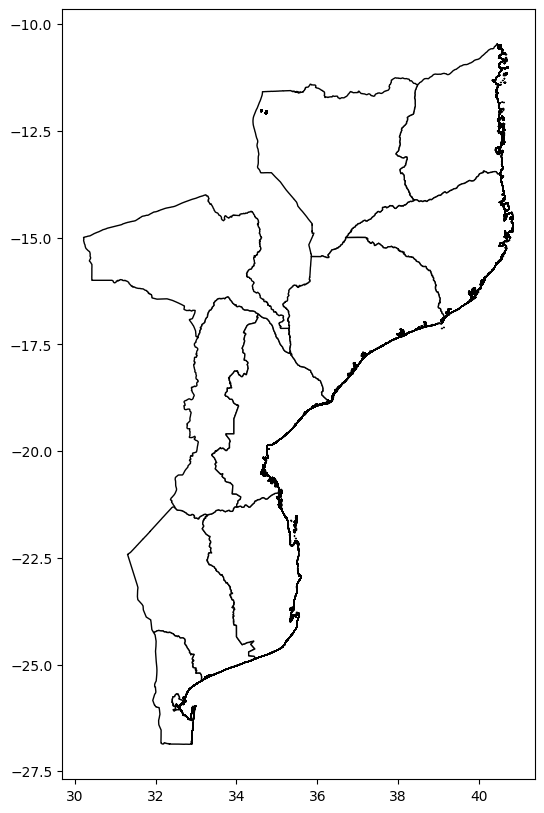

In [51]:
plot_disruption_schools(disrupted_schools, impp1_direct, impp1_disrupted, gadm_MOZ, output_dir)

In [ ]:
### Road 

In [52]:
import os
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import BoundaryNorm, ListedColormap
import geopandas as gpd
import numpy as np
from datetime import datetime

def truncate_colormap(cmap_name, minval=0.2, maxval=1.0, n=256):
    cmap = plt.get_cmap(cmap_name)
    return ListedColormap(cmap(np.linspace(minval, maxval, n)))

def plot_road_disruption(rd2_disrupted, impp1_direct, impp1_disrupted, gadm_MOZ, output_dir):
    os.makedirs(output_dir, exist_ok=True)

    gadm_MOZ = gadm_MOZ.to_crs("EPSG:4326")
    cmap_purple = ListedColormap(plt.get_cmap("Purples")(np.linspace(0.3, 1.0, 6)))
    cmap_green = ListedColormap(plt.get_cmap("Greens")(np.linspace(0.3, 1.0, 6)))
    cmap_road = truncate_colormap('viridis', 0.2, 1.0)

    for key in rd2_disrupted:
        impp1_key = f"impp1_MOZ_Kenneth_{key}" 
        if impp1_key not in impp1_direct or impp1_key not in impp1_disrupted:
            print(f"Skipping {key} due to missing impp1 data.")
            continue

        try:
            gdf_base = impp1_direct[impp1_key].to_crs("EPSG:4326")
            gdf_overlay = impp1_disrupted[impp1_key].to_crs("EPSG:4326")
            roads_df = rd2_disrupted[key].copy()

            if 'geometry_orig' not in roads_df.columns or 'n_ensemble_members' not in roads_df.columns:
                print(f"Skipping {key}: 'geometry_orig' or 'n_ensemble_members' not found.")
                continue

            roads_df = gpd.GeoDataFrame(roads_df, geometry=roads_df['geometry_orig'], crs="EPSG:4326")
            roads_df = roads_df[roads_df['n_ensemble_members'] >= 5]

            gdf_base = gpd.sjoin(gdf_base, gadm_MOZ[['geometry']], how='inner', predicate='within').drop(columns='index_right')
            gdf_overlay = gpd.sjoin(gdf_overlay, gadm_MOZ[['geometry']], how='inner', predicate='within').drop(columns='index_right')
            roads_df = gpd.sjoin(roads_df, gadm_MOZ[['geometry']], how='inner', predicate='intersects').drop(columns='index_right')

            gdf_base = gdf_base[gdf_base['people'] > 0]
            gdf_overlay = gdf_overlay[gdf_overlay['people'] > 0]

            vmax_base = gdf_base['people'].max() if not gdf_base.empty else 1
            vmax_overlay = gdf_overlay['people'].max() if not gdf_overlay.empty else 1

            base_bins = np.linspace(0, vmax_base, 7)
            overlay_bins = np.linspace(0, vmax_overlay, 7)

            norm_base = BoundaryNorm(base_bins, cmap_purple.N, clip=True)
            norm_overlay = BoundaryNorm(overlay_bins, cmap_green.N, clip=True)
            norm_road = mcolors.Normalize(vmin=5, vmax=51)

            base_colors = [cmap_purple(norm_base(val)) for val in gdf_base['people']]
            overlay_colors = [cmap_green(norm_overlay(val)) for val in gdf_overlay['people']]

            dt_obj = datetime.strptime(key, "%Y%m%d%H%M%S")
            formatted_date = dt_obj.strftime("forecast date: %a %d %B %Y %H UTC")

            fig, ax = plt.subplots(figsize=(10, 10))
            gadm_MOZ.plot(ax=ax, color='white', edgecolor='black', zorder=0)
            gdf_base.plot(ax=ax, markersize=10, color=base_colors, edgecolor='none', alpha=0.85, zorder=1)
            gdf_overlay.plot(ax=ax, markersize=10, color=overlay_colors, edgecolor='none', alpha=0.85, zorder=2)
            roads_df.plot(ax=ax, column='n_ensemble_members', cmap=cmap_road, linewidth=1.5, alpha=0.8, zorder=3)

            sm_base = plt.cm.ScalarMappable(cmap=cmap_purple, norm=norm_base)
            sm_base.set_array([])
            cb1 = plt.colorbar(sm_base, ax=ax, orientation='horizontal', pad=0.02, shrink=0.6)
            cb1.set_label('People direct affected')
            cb1.set_ticks(base_bins)
            cb1.ax.tick_params(labelsize=10)

            sm_overlay = plt.cm.ScalarMappable(cmap=cmap_green, norm=norm_overlay)
            sm_overlay.set_array([])
            cb2 = plt.colorbar(sm_overlay, ax=ax, orientation='horizontal', pad=0.08, shrink=0.6)
            cb2.set_label('People disrupted cat.1')
            cb2.set_ticks(overlay_bins)
            cb2.ax.tick_params(labelsize=10)

            sm_road = plt.cm.ScalarMappable(cmap=cmap_road, norm=norm_road)
            sm_road.set_array([])
            cb3 = plt.colorbar(sm_road, ax=ax, orientation='vertical', pad=0.01, shrink=0.5)
            cb3.set_label('Disrupted Ensemble Members (Roads)')

            ax.set_title(f'{formatted_date}', fontsize=25)
            ax.set_xlabel("Longitude")
            ax.set_ylabel("Latitude")
            ax.set_xlim(32, 42)
            ax.set_ylim(-15, -11)

            plt.tight_layout()
            filename = os.path.join(output_dir, f'disruption_rd2_{key}.png')
            plt.savefig(filename, dpi=300)
            plt.close()

        except Exception as e:
            print(f"Error processing {key}: {e}")

Error processing 20190423120000: aspect must be finite and positive 


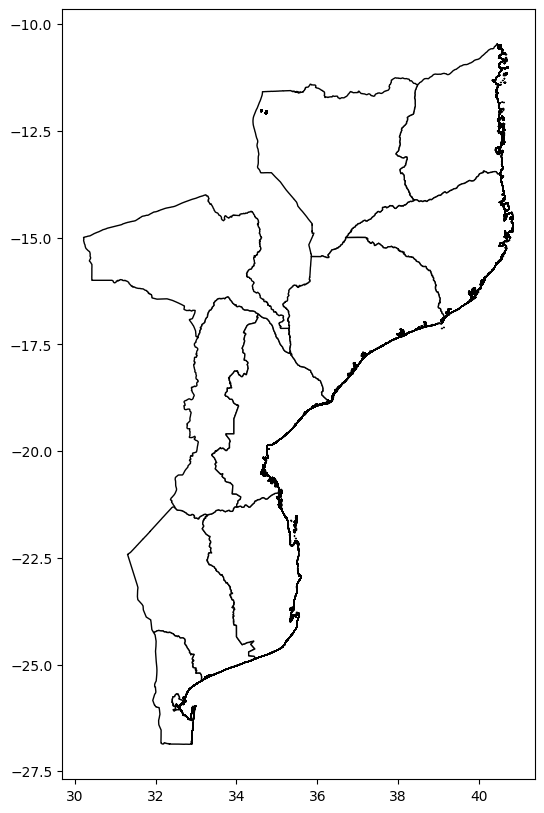

In [53]:
plot_road_disruption(rd2_disrupted, impp1_direct, impp1_disrupted, gadm_MOZ, "/cluster/home/gespejo/MOZ_struc_plots_Kenneth/")

In [ ]:
### Legends 

In [143]:
import os
import matplotlib.pyplot as plt

def plot_only_hospital_legend(output_path):
    import geopandas as gpd

    # Define markers and styles
    level_markers = {1: 'o', 2: 's', 3: '^', 4: 'D'}
    level_style = {
        1: {'alpha': 0.8, 'edgecolor': 'indigo', 'facecolor': 'indigo', 's': 100},
        2: {'alpha': 0.8, 'edgecolor': 'mediumslateblue', 'facecolor': 'mediumslateblue', 's': 100},
        3: {'alpha': 0.8, 'edgecolor': 'darkmagenta', 'facecolor': 'darkmagenta', 's': 100},
        4: {'alpha': 0.8, 'edgecolor': 'mediumvioletred', 'facecolor': 'mediumvioletred', 's': 100},
    }

    # Create dummy points for legend
    fig, ax = plt.subplots(figsize=(6, 4))

    handles = []
    labels = []
    for level in sorted(level_markers.keys()):
        style = level_style[level]
        h = ax.scatter([], [], marker=level_markers[level], 
                       edgecolor=style['edgecolor'], facecolor=style['facecolor'],
                       alpha=style['alpha'], s=style['s'])
        handles.append(h)
        labels.append(f'Health Facility Level {level}')

    # Plot only the legend
    ax.legend(handles, labels, title="Hospital Levels", loc='center', fontsize=11, title_fontsize=12)
    ax.axis('off')

    # Save
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.close()

# Example usage
plot_only_hospital_legend("/cluster/home/gespejo/MOZ_struc_plots_Freddy/hospital_levels_legend_only.png")

In [145]:
import os
import matplotlib.pyplot as plt

def plot_only_school_legend(output_path):
    # Create dummy point for legend
    fig, ax = plt.subplots(figsize=(4, 3))

    # Create dummy handle for blue school dot
    handle = ax.scatter([], [], color='blue', edgecolor='blue', s=100, alpha=0.8)
    ax.legend([handle], ["Disrupted Schools"], loc='center', fontsize=11, title_fontsize=12)

    ax.axis('off')

    # Save the figure
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.close()

# Example usage
plot_only_school_legend("/cluster/home/gespejo/MOZ_struc_plots_Freddy/schools_legend_only.png")